# 1969 — *Perceptrons* and the XOR Problem

**Book:** Marvin Minsky & Seymour Papert, *Perceptrons* (1969).

They proved rigorously what single-layer perceptrons **cannot** compute. The famous example is XOR:

| $x_1$ | $x_2$ | XOR |
|---|---|---|
| 0 | 0 | 0 |
| 0 | 1 | 1 |
| 1 | 0 | 1 |
| 1 | 1 | 0 |

**Proof sketch.** Suppose $w_1x_1 + w_2x_2 \ge \theta$ fires exactly for XOR. Then $0 < \theta$ (from (0,0)), $w_1 \ge \theta$ and $w_2 \ge \theta$ (from (1,0),(0,1)), so $w_1 + w_2 \ge 2\theta > \theta$ — but (1,1) must *not* fire. Contradiction.

The book is often blamed for the first "AI winter" in neural network research. The way out — hidden layers trained by backpropagation — came in 1986.

![Diagram: XOR needs a hidden layer (Minsky & Papert, 1969)](https://raw.githubusercontent.com/babushkai/neuralnetwork/main/assets/diagrams/04_1969_xor_problem.png)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
rng = np.random.default_rng(0)

X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)
y_xor = np.array([-1, 1, 1, -1])
y_and = np.array([-1, -1, -1, 1])

def train_perceptron(X, y, epochs=100):
    w, b, hist = np.zeros(X.shape[1]), 0.0, []
    for _ in range(epochs):
        mistakes = 0
        for i in range(len(X)):
            if y[i] * (X[i] @ w + b) <= 0:
                w += y[i] * X[i]; b += y[i]; mistakes += 1
        hist.append(mistakes)
    return w, b, hist

## The perceptron learns AND but never settles on XOR

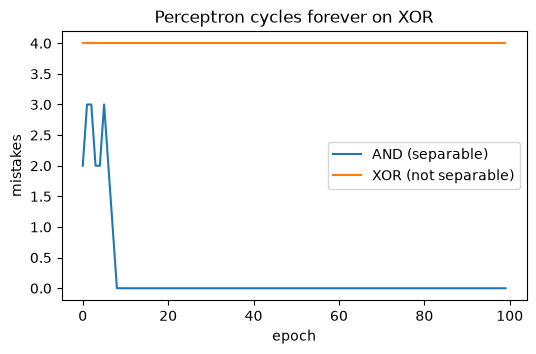

mistakes in last 10 epochs — AND: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0]  XOR: [4, 4, 4, 4, 4, 4, 4, 4, 4, 4]


In [2]:
_, _, h_and = train_perceptron(X, y_and)
_, _, h_xor = train_perceptron(X, y_xor)
plt.figure(figsize=(6, 3.5))
plt.plot(h_and, label="AND (separable)")
plt.plot(h_xor, label="XOR (not separable)")
plt.xlabel("epoch"); plt.ylabel("mistakes"); plt.legend(); plt.title("Perceptron cycles forever on XOR")
plt.show()
print("mistakes in last 10 epochs — AND:", h_and[-10:], " XOR:", h_xor[-10:])

## Brute-force check: no line works
Search a dense grid of $(w_1, w_2, b)$ — the best any linear threshold unit can do on XOR is 3/4.

In [3]:
grid = np.linspace(-2, 2, 41)
best = 0
for w1 in grid:
    for w2 in grid:
        for b in grid:
            acc = (np.where(X @ [w1, w2] + b >= 0, 1, -1) == y_xor).mean()
            best = max(best, acc)
print("best accuracy of any linear threshold unit on XOR:", best)

best accuracy of any linear threshold unit on XOR: 0.75


## Way out #1: change the features
Add the product feature $x_1x_2$. In 3-D the points become linearly separable — this is what a **hidden layer** learns to do automatically.

In [4]:
X3 = np.c_[X, X[:, 0] * X[:, 1]]
w, b, h = train_perceptron(X3, y_xor)
print("with x1*x2 feature: mistakes in last epoch =", h[-1], "| weights", w, "bias", b)
print("predictions:", np.where(X3 @ w + b >= 0, 1, -1), "targets:", y_xor)

with x1*x2 feature: mistakes in last epoch = 0 | weights [ 2.  2. -5.] bias -1.0
predictions: [-1  1  1 -1] targets: [-1  1  1 -1]


## Way out #2: a hidden layer (hand-wired)
Two hidden threshold units (OR and NAND) followed by an AND unit compute XOR. The open problem in 1969 was **how to learn** such hidden weights — answered by backpropagation (see `08_1986_backpropagation_mlp`).

hidden layer:
 [[0 1]
 [1 1]
 [1 1]
 [1 0]] 
output: [0 1 1 0]


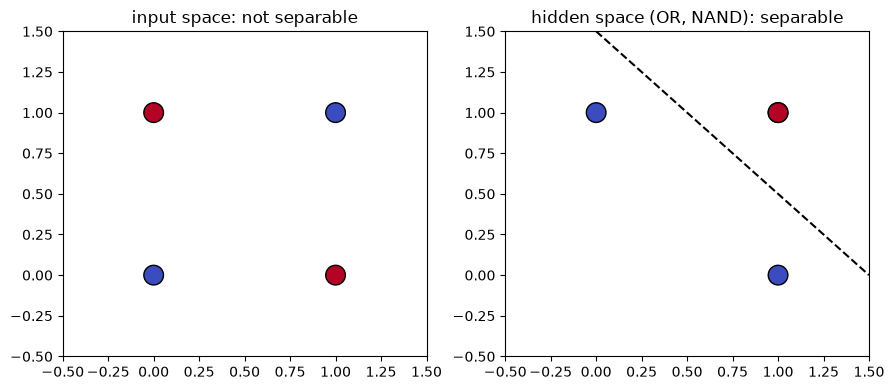

In [5]:
step = lambda z: (z >= 0).astype(int)
H = step(np.c_[X @ [1, 1] - 0.5, X @ [-1, -1] + 1.5])   # OR, NAND
out = step(H @ [1, 1] - 1.5)                          # AND
print("hidden layer:\n", H, "\noutput:", out)

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, (title, pts, lab) in zip(axes, [("input space: not separable", X, y_xor), ("hidden space (OR, NAND): separable", H, y_xor)]):
    ax.scatter(pts[:, 0], pts[:, 1], c=lab, cmap="coolwarm", s=200, edgecolor="k")
    ax.set_title(title); ax.set_xlim(-0.5, 1.5); ax.set_ylim(-0.5, 1.5)
axes[1].plot([0, 1.5], [1.5, 0], "k--")   # x + y = 1.5
plt.tight_layout(); plt.show()